# Simple graph example

Loaded 8 nodes, 9 edges


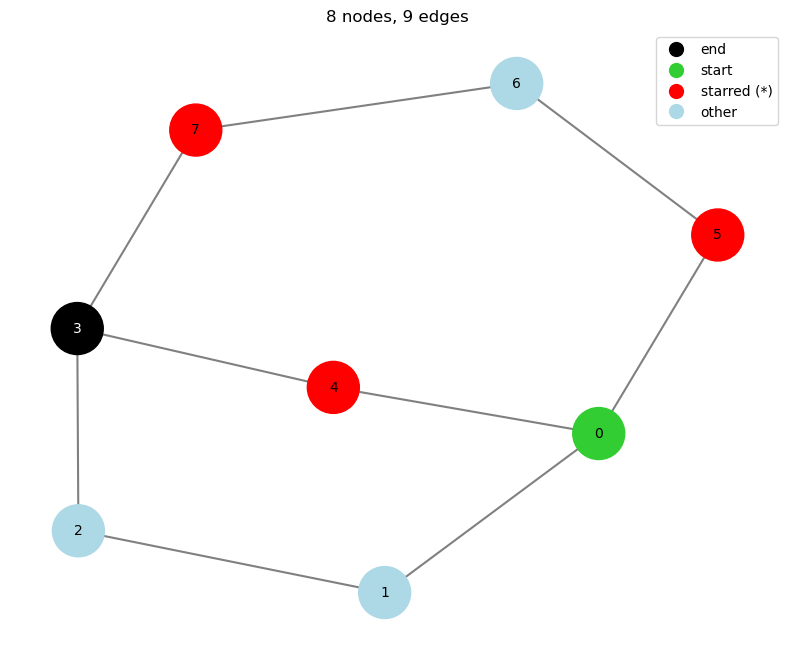

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FILE = "problem_and_data/data/G-ex.txt"
KEEP_END = False   # True keeps the end node even if it has no edges


def load_graph(path):
    with open(path) as f:
        lines = [ln.strip() for ln in f if ln.strip()]

    n, m, k = map(int, lines[0].split())   # nodes, edges, starred
    start, end = lines[1].split()

    G = nx.Graph()
    for ln in lines[2:2 + n]:
        parts = ln.split()
        G.add_node(parts[0], starred=(len(parts) > 1 and parts[1] == "*"))

    for ln in lines[2 + n:2 + n + m]:
        a, b = [p.strip() for p in ln.split("--")]
        G.add_edge(a, b)

    return G, start, end


G, start, end = load_graph(FILE)
print(f"Loaded {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

# Remove nodes with no edges
isolated = [v for v in nx.isolates(G) if not (KEEP_END and v == end)]
G.remove_nodes_from(isolated)

# Colours: end = black/white font, starred = red, others = light blue
node_colors, label_colors = {}, {}
for node, data in G.nodes(data=True):
    if node == end:
        node_colors[node], label_colors[node] = "black", "white"
    elif node == start:
        node_colors[node], label_colors[node] = "limegreen", "black"
    elif data["starred"]:
        node_colors[node], label_colors[node] = "red", "black"
    else:
        node_colors[node], label_colors[node] = "lightblue", "black"

pos = nx.spring_layout(G, seed=40, k=0.8)

plt.figure(figsize=(10, 8))
nx.draw_networkx_edges(G, pos, edge_color="gray", width=1.5)
nx.draw_networkx_nodes(G, pos, node_size=1400,
                       node_color=[node_colors[n] for n in G.nodes])
for node, (x, y) in pos.items():
    plt.text(x, y, node, ha="center", va="center",
             fontsize=10, color=label_colors[node])

legend_items = [("red", "starred (*)"), ("lightblue", "other")]
if end in G:
    legend_items.insert(1, ("limegreen", "start"))
    legend_items.insert(0, ("black", "end"))
plt.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=12, label=l)
    for c, l in legend_items
])

plt.title(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
plt.axis("off")
plt.show()

# Grid graph example

Loaded 100 nodes, 261 edges


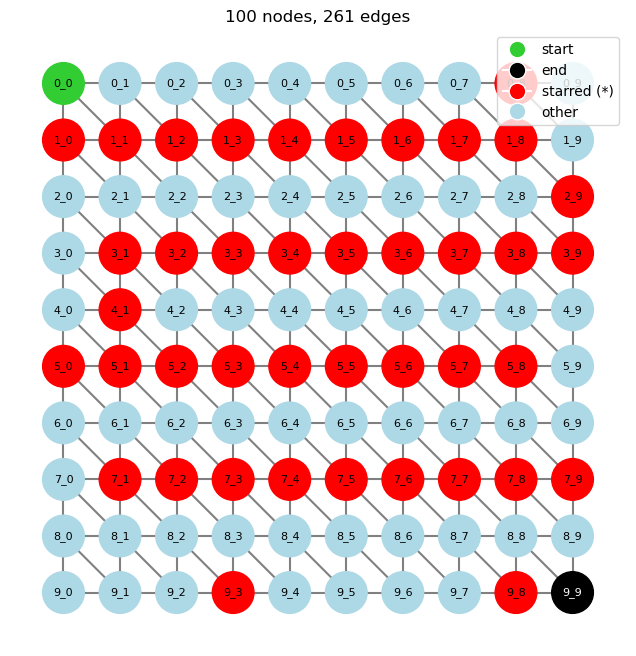

In [2]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FILE = "problem_and_data/data/grid-10-2.txt"
KEEP_END = False   # True keeps the end node even if it has no edges


def load_graph(path):
    with open(path) as f:
        lines = [ln.strip() for ln in f if ln.strip()]

    n, m, k = map(int, lines[0].split())
    start, end = lines[1].split()

    G = nx.Graph()
    for ln in lines[2:2 + n]:
        parts = ln.split()
        G.add_node(parts[0], starred=(len(parts) > 1 and parts[1] == "*"))

    for ln in lines[2 + n:2 + n + m]:
        a, b = [p.strip() for p in ln.split("--")]
        G.add_edge(a, b)

    return G, start, end


def grid_positions(G):
    """Node 'r_c' -> (x, y). Row 0 is drawn at the top."""
    pos = {}
    for node in G.nodes:
        r, c = map(int, node.split("_"))
        pos[node] = (c, -r)          # x = column, y = -row
    return pos


G, start, end = load_graph(FILE)
print(f"Loaded {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

isolated = [v for v in nx.isolates(G) if not (KEEP_END and v == end)]
G.remove_nodes_from(isolated)

node_colors, label_colors = {}, {}
for node, data in G.nodes(data=True):
    if node == end:
        node_colors[node], label_colors[node] = "black", "white"
    elif node == start:
        node_colors[node], label_colors[node] = "limegreen", "black"
    elif data["starred"]:
        node_colors[node], label_colors[node] = "red", "black"
    else:
        node_colors[node], label_colors[node] = "lightblue", "black"

pos = grid_positions(G)

plt.figure(figsize=(8, 8))
nx.draw_networkx_edges(G, pos, edge_color="gray", width=1.5)
nx.draw_networkx_nodes(G, pos, node_size=900,
                       node_color=[node_colors[n] for n in G.nodes])
for node, (x, y) in pos.items():
    plt.text(x, y, node, ha="center", va="center",
             fontsize=8, color=label_colors[node])

plt.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=12, label=l)
    for c, l in [("limegreen", "start"), ("black", "end"), ("red", "starred (*)"), ("lightblue", "other")]
])
plt.title(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
plt.gca().set_aspect("equal")
plt.axis("off")
plt.show()

# Walls grapgh example

In [5]:
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

FILE = "problem_and_data/data/wall-n-1.txt"
KEEP_END = False   # True keeps the end node even if it has no edges


def load_graph(path):
    with open(path) as f:
        lines = [ln.strip() for ln in f if ln.strip()]

    n, m, k = map(int, lines[0].split())
    start, end = lines[1].split()

    G = nx.Graph()
    for ln in lines[2:2 + n]:
        parts = ln.split()
        G.add_node(parts[0], starred=(len(parts) > 1 and parts[1] == "*"))

    for ln in lines[2 + n:2 + n + m]:
        a, b = [p.strip() for p in ln.split("--")]
        G.add_edge(a, b)

    return G, start, end


def grid_positions(G):
    """Node 'r_c' -> (x, y). Row 0 is drawn at the top."""
    pos = {}
    for node in G.nodes:
        r, c = map(int, node.split("_"))
        pos[node] = (c, -r)          # x = column, y = -row
    return pos


G, start, end = load_graph(FILE)
print(f"Loaded {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")

isolated = [v for v in nx.isolates(G) if not (KEEP_END and v == end)]
G.remove_nodes_from(isolated)

node_colors, label_colors = {}, {}
for node, data in G.nodes(data=True):
    if node == end:
        node_colors[node], label_colors[node] = "black", "white"
    elif node == start:
        node_colors[node], label_colors[node] = "limegreen", "black"
    elif data["starred"]:
        node_colors[node], label_colors[node] = "red", "black"
    else:
        node_colors[node], label_colors[node] = "lightblue", "black"

pos = grid_positions(G)

plt.figure(figsize=(8, 8))
nx.draw_networkx_edges(G, pos, edge_color="gray", width=1.5)
nx.draw_networkx_nodes(G, pos, node_size=900,
                       node_color=[node_colors[n] for n in G.nodes])
for node, (x, y) in pos.items():
    plt.text(x, y, node, ha="center", va="center",
             fontsize=8, color=label_colors[node])

plt.legend(handles=[
    Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=12, label=l)
    for c, l in [("limegreen", "start"), ("black", "end"), ("red", "starred (*)"), ("lightblue", "other")]
])
plt.title(f"{G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
plt.gca().set_aspect("equal")
plt.axis("off")
plt.show()

Loaded 8 nodes, 8 edges


ValueError: not enough values to unpack (expected 2, got 1)